# NGB: original vs augmented images

This notebook reads `Ma190c_annotations.dat`, selects class `NGB`, and shows original images next to augmented variants (`_augXXX`).

In [1]:
from pathlib import Path
from collections import defaultdict, Counter
import random
import textwrap

import numpy as np
import matplotlib.pyplot as plt
import tifffile

ANNOTATIONS_PATH = Path(r"C:\\Users\\gabriele.dangeli\\Dataset\\microscopy\\labels\\Ma190c_annotations.dat")
RAW_DIR = Path(r"C:\\Users\\gabriele.dangeli\\Dataset\\microscopy\\images\\raw_scale100")
AUG_DIR = Path(r"C:\\Users\\gabriele.dangeli\\Dataset\\microscopy\\images_augmented\\raw_scale100")
CLASS_NAME = "NGB"

for p in (ANNOTATIONS_PATH, RAW_DIR, AUG_DIR):
    print(f"{p}: {'OK' if p.exists() else 'MISSING'}")


C:\Users\gabriele.dangeli\Dataset\microscopy\labels\Ma190c_annotations.dat: OK
C:\Users\gabriele.dangeli\Dataset\microscopy\images\raw_scale100: OK
C:\Users\gabriele.dangeli\Dataset\microscopy\images_augmented\raw_scale100: OK


In [2]:
def parse_annotations(path: Path):
    rows = []
    with path.open("r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 2:
                rows.append((parts[0], parts[1]))
    return rows


def collect_augmented_by_base(aug_dir: Path, suffix: str = "_aug"):
    by_base = defaultdict(list)
    for img_path in sorted(aug_dir.glob("*.tiff")):
        stem = img_path.stem
        if suffix in stem:
            base = stem.rsplit(suffix, 1)[0]
            by_base[base].append(img_path)
    return by_base


def read_tiff(path: Path):
    arr = tifffile.imread(path).astype(np.float32)
    arr = np.squeeze(arr)
    if arr.ndim != 2:
        raise ValueError(f"Expected 2D image, got shape {arr.shape} for {path}")
    return arr


def normalize_for_display(arr: np.ndarray, low: float = 1, high: float = 99):
    lo, hi = np.percentile(arr, [low, high])
    if hi <= lo:
        return np.zeros_like(arr, dtype=np.float32)
    out = (arr - lo) / (hi - lo)
    return np.clip(out, 0.0, 1.0)


In [3]:
rows = parse_annotations(ANNOTATIONS_PATH)
ngb_ids = sorted([image_id for image_id, label in rows if label == CLASS_NAME])
aug_by_base = collect_augmented_by_base(AUG_DIR)
ngb_raw_ids = [image_id for image_id in ngb_ids if (RAW_DIR / f"{image_id}.tiff").exists()]
ngb_with_aug = [image_id for image_id in ngb_raw_ids if image_id in aug_by_base]

print(f"Total labels: {len(rows)}")
print(f"NGB labels: {len(ngb_ids)}")
print(f"NGB with original raw file: {len(ngb_raw_ids)}")
print(f"NGB with at least one augmented file: {len(ngb_with_aug)}")

top_aug = sorted(((k, len(v)) for k, v in aug_by_base.items() if k in ngb_raw_ids), key=lambda x: x[1], reverse=True)
print("Top NGB originals by number of augmentations:")
for base_id, count in top_aug[:10]:
    print(f"  {base_id}: {count}")


Total labels: 950
NGB labels: 8
NGB with original raw file: 8
NGB with at least one augmented file: 2
Top NGB originals by number of augmentations:
  Ma190c_lame15_zone5_composite_Mcropped_1: 25
  Ma190c_lame1_zone13_composite_Mcropped_1: 25


In [4]:
def _format_plot_title(text: str, shorten_width: int = 48, line_width: int = 20):
    cleaned = text.replace("_", " ")
    shortened = textwrap.shorten(cleaned, width=shorten_width, placeholder="...")
    return textwrap.fill(shortened, width=line_width)


def show_original_and_augmented(base_id: str, max_aug: int = 6, random_order: bool = False, seed: int = 0):
    raw_path = RAW_DIR / f"{base_id}.tiff"
    if not raw_path.exists():
        raise FileNotFoundError(f"Original image not found: {raw_path}")

    aug_paths = list(aug_by_base.get(base_id, []))
    if random_order and len(aug_paths) > 1:
        rnd = random.Random(seed)
        rnd.shuffle(aug_paths)
    aug_paths = aug_paths[:max_aug]

    n_cols = 1 + len(aug_paths)
    fig, axes = plt.subplots(1, n_cols, figsize=(3.8 * n_cols, 4.8))
    if n_cols == 1:
        axes = [axes]

    axes[0].imshow(normalize_for_display(read_tiff(raw_path)), cmap="gray")
    axes[0].set_title("Original", fontsize=10, pad=10)
    axes[0].axis("off")

    for ax, aug_path in zip(axes[1:], aug_paths):
        ax.imshow(normalize_for_display(read_tiff(aug_path)), cmap="gray")
        ax.set_title(_format_plot_title(aug_path.stem), fontsize=8, pad=10)
        ax.axis("off")

    fig.suptitle(_format_plot_title(f"{base_id} | class={CLASS_NAME}", shorten_width=90, line_width=45), fontsize=12, y=0.98)
    fig.tight_layout(rect=[0, 0.02, 1, 0.90])
    plt.show()

    if not aug_paths:
        print("No augmented variants found for this image.")


Selected NGB image IDs:
  - Ma190c_lame15_zone5_composite_Mcropped_1
  - Ma190c_lame1_zone13_composite_Mcropped_1


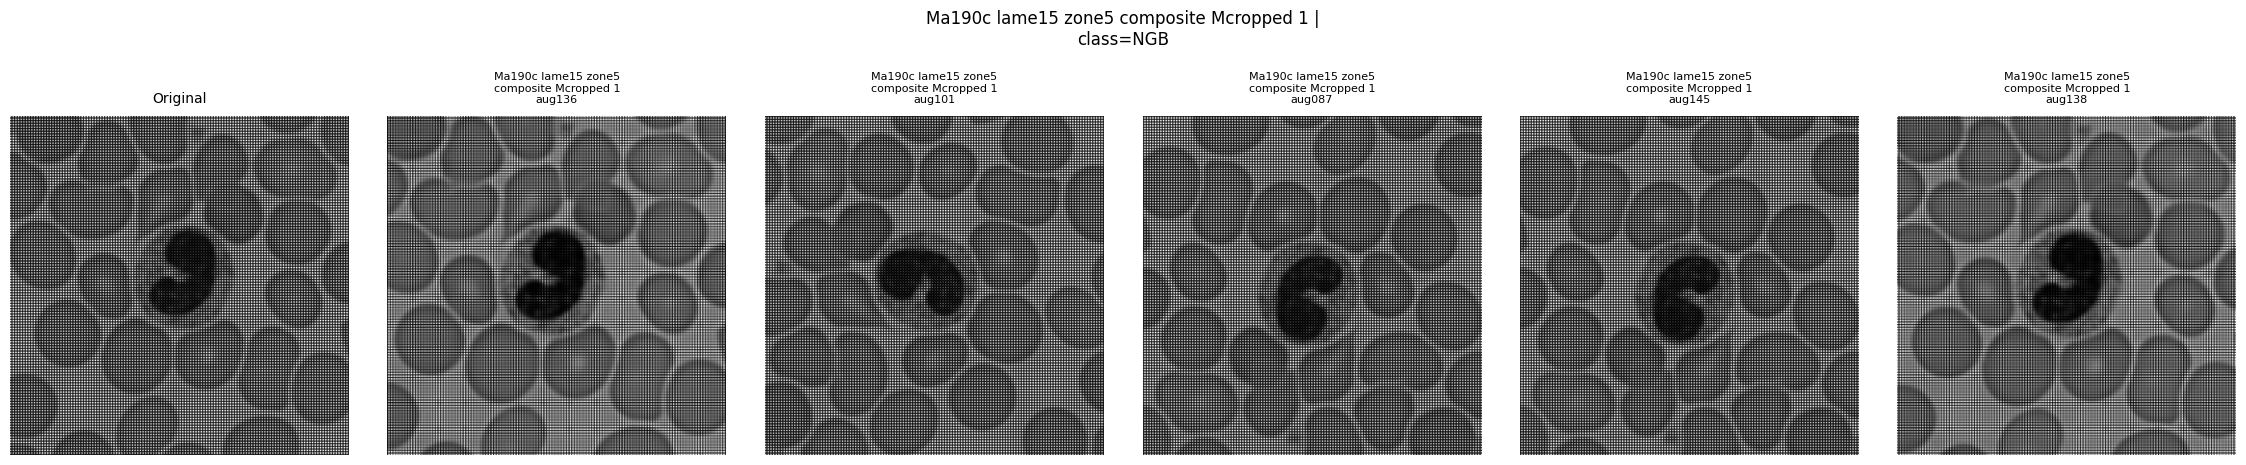

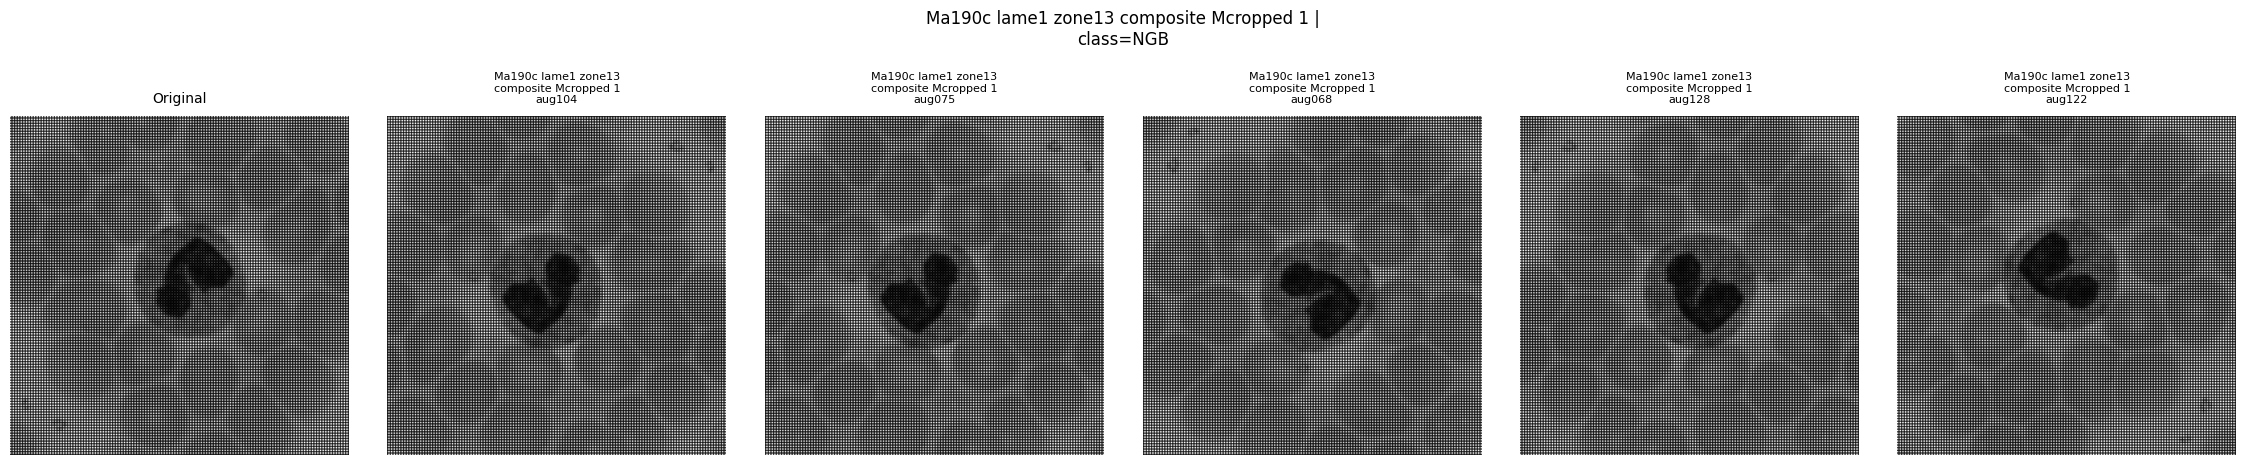

In [5]:
EXAMPLES = 5
MAX_AUG_PER_EXAMPLE = 5
SEED = 42

if not ngb_with_aug:
    print("No NGB image has augmented variants in AUG_DIR.")
else:
    rng = random.Random(SEED)
    chosen = ngb_with_aug if len(ngb_with_aug) <= EXAMPLES else rng.sample(ngb_with_aug, EXAMPLES)
    print("Selected NGB image IDs:")
    for image_id in chosen:
        print(f"  - {image_id}")
    for image_id in chosen:
        show_original_and_augmented(image_id, max_aug=MAX_AUG_PER_EXAMPLE, random_order=True, seed=SEED)


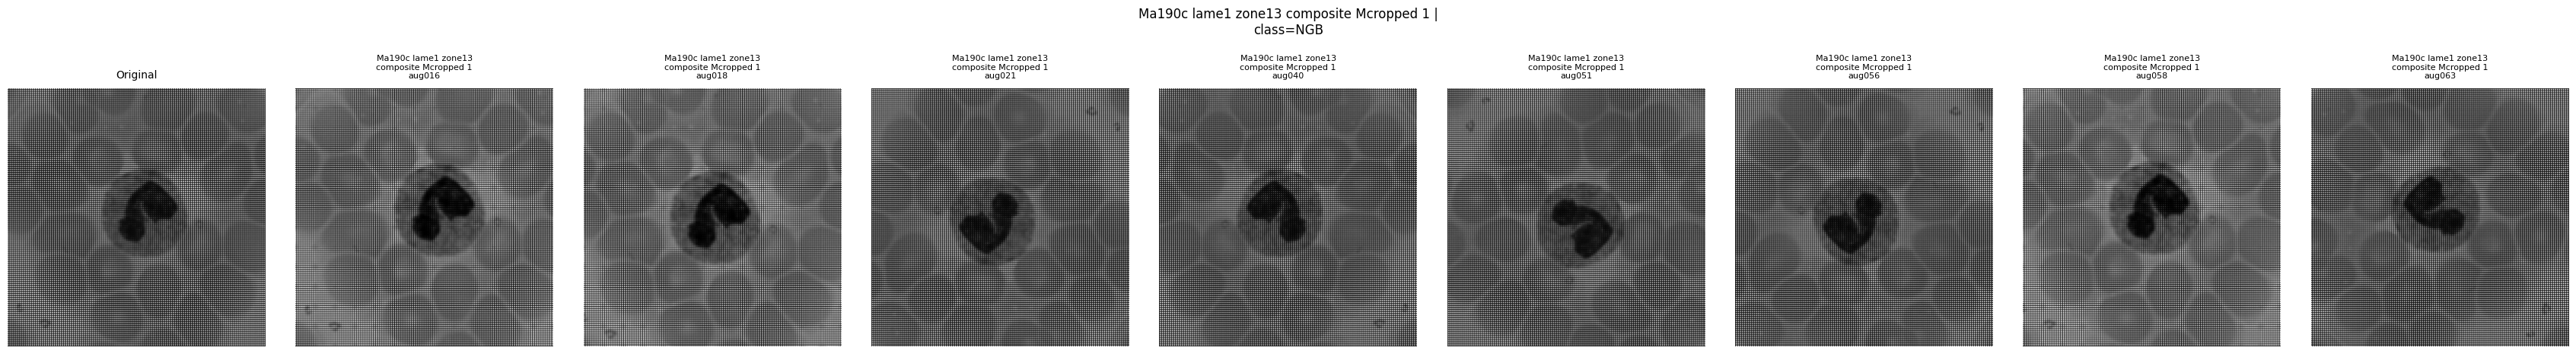

In [6]:
# Optional: inspect one specific NGB image ID
BASE_ID = "Ma190c_lame1_zone13_composite_Mcropped_1"
show_original_and_augmented(BASE_ID, max_aug=8, random_order=False)
